In [88]:
import xarray as xr
import numpy as np
import pandas as pd
from scipy import ndimage
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import warnings
import time

from mhw_detection_functions import *

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

## NOAA OI SST V2 High Resolution Dataset

Source: https://psl.noaa.gov/data/gridded/data.noaa.oisst.v2.highres.html

Dataset Specifications:
- Daily values from 1981/09 to 2026/09
- 0.25 degree latitude x 0.25 degree longitude global grid (1440x720)

In [82]:
raw = xr.open_dataset('data/noaa_oisst/noaa_oisst_aus_1981_2026.nc')
raw

<xarray.Dataset>
Dimensions:  (time: 16461, lon: 280, lat: 220)
Coordinates:
  * time     (time) datetime64[ns] 1981-09-01 1981-09-02 ... 2026-09-25
  * lon      (lon) float32 110.1 110.4 110.6 110.9 ... 179.1 179.4 179.6 179.9
  * lat      (lat) float32 -54.88 -54.62 -54.38 -54.12 ... -0.625 -0.375 -0.125
Data variables:
    sst      (time, lat, lon) float32 ...
Attributes:
    CDI:            Climate Data Interface version 1.9.10 (https://mpimet.mpg...
    source:         NOAA/NCDC  ftp://eclipse.ncdc.noaa.gov/pub/OI-daily-v2/
    institution:    NOAA/NCDC
    Conventions:    CF-1.5
    title:          NOAA High-resolution Blended Analysis: Daily Values using...
    dataset_title:  NOAA Daily Optimum Interpolation Sea Surface Temperature
    References:     https://www.psl.noaa.gov/data/gridded/data.noaa.oisst.v2....
    comment:        Reynolds, et al.(2007) Daily High-Resolution-Blended Anal...
    CDO:            Climate Data Operators version 1.9.10 (https://mpimet.mpg...
    history:        27-Sep-2026 03:32:35 Subset NOAA/PSL

In [92]:
var_names = {"sst": "temp"}
raw = raw.rename(var_names)

daily = resample_daily(raw, var="temp")

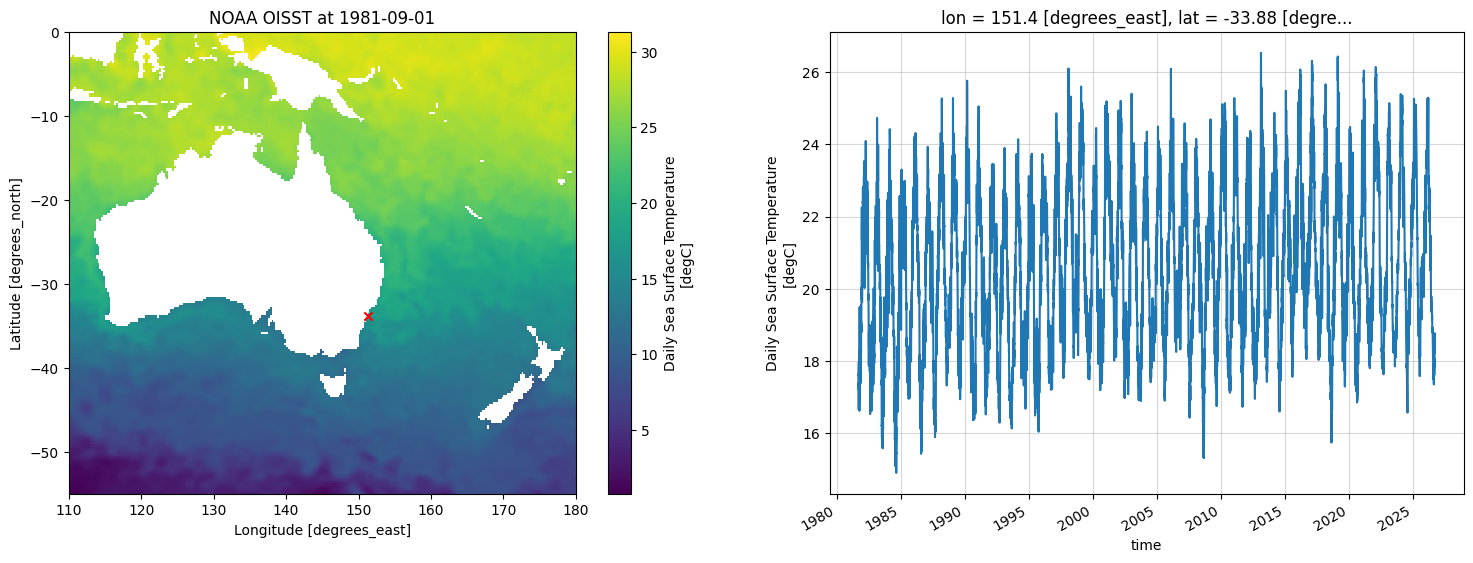

In [ ]:
# location off the coast of Sydney, chosen based on proximity to IMOS dataset:
# data/IMOS_ANMN-NSW_TZ_20060608_ORS065_FV02_TEMP-gridded-timeseries_END-20251203_C-20260523.nc
lon_sel, lat_sel = 151.3, -33.8

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(18, 6))

daily.isel(time=0).plot(cmap='viridis', ax=ax1)
ax1.scatter(lon_sel, lat_sel, marker='x', c='red')
ax1.set_title(f"NOAA OISST at {daily.isel(time=0).time.dt.strftime('%Y-%m-%d').item()}")

daily.sel(lat=lat_sel, lon=lon_sel, method='nearest').plot(ax=ax2)
ax2.grid(alpha=0.5)

In [ ]:
# var_names = {"sst": "temp"}

# daily_single = resample_daily(raw, var="temp").sel(lat=lat_sel, lon=lon_sel, method='nearest')

# baseline = daily_single.sel(time=slice("1981-09-01", "2011-09-01"))

# threshold_specs = make_threshold_specs(
#     quantiles=np.arange(0.7, 0.999, 0.001),
#     offsets=np.arange(0.0, 4.01, 0.01),
#     std_multiples=np.arange(0.0, 4.01, 0.01),
# )

# result = run_mhw_detection(
#     daily=daily_single,
#     baseline=baseline,
#     threshold_specs=threshold_specs,
#     pool_window=11,
#     smooth_window=31,
#     min_samples=30,
#     max_gap=2,
#     min_duration=5,
#     validate_nesting=False,
#     multiindex=True,
# )

# result["data"].to_netcdf("data/noaa_oisst/oisst_syd_events_data.nc")
# result["events"].to_pickle("data/noaa_oisst/oisst_syd_events_catalogue.pkl")

# proc time ~ 4m 40s
# START : 0.30 GB RSS
# AFTER  compute_climatology_stats: 0.31 GB RSS
# AFTER  build_threshold_climatology: 0.31 GB RSS
# AFTER  prepare_mhw_data: 0.38 GB RSS
# AFTER  exceedance: 0.39 GB RSS
# AFTER  raw_nesting: 0.45 GB RSS
# AFTER  detect_exceedance_events: 0.49 GB RSS
# AFTER  event_nesting: 0.50 GB RSS
# AFTER  label_exceedance_events: 0.57 GB RSS
# AFTER  compute_exceedance_event_metrics: 0.57 GB RSS
# END : 0.57 GB RSS

In [105]:
# NOAA OISST
mhw_events_oisst = pd.read_pickle("data/noaa_oisst/oisst_syd_events_catalogue.pkl")
mhw_all_data_oisst = xr.open_dataset("data/noaa_oisst/oisst_syd_events_data.nc")

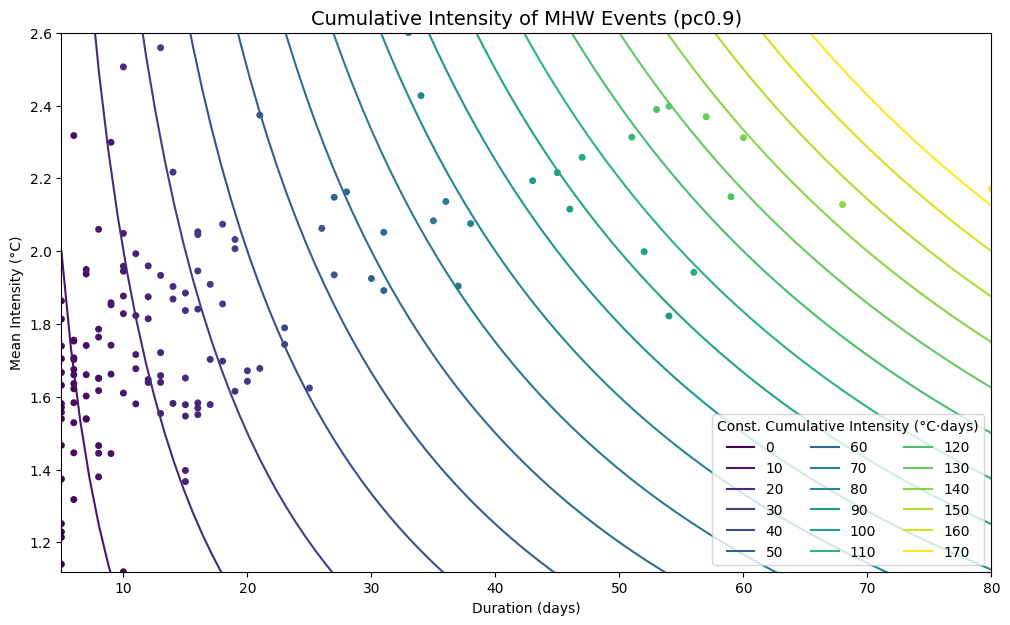

In [106]:
method = "quantile"
value = 0.9

mhw_events_plot = select_events_by_threshold(mhw_events_oisst, "quantile", value)

fig, ax = plt.subplots(figsize=(12, 7))

# plot surfaces of constant cumulative intensity
const_cum_i = list(range(0,round(mhw_events_plot.cumulative_intensity.max())+1,10))
cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0, 1, len(const_cum_i)))
duration_range = np.linspace(mhw_events_plot.duration.min(), mhw_events_plot.duration.max(), 100)
for i in range(len(const_cum_i)):
    cum_i = const_cum_i[i]
    plt.plot(duration_range, cum_i / duration_range, label=f"{cum_i}", color=colors[i])

# plot events by mean intensity vs duration, colored by cumulative intensity
sc = ax.scatter(
    mhw_events_plot["duration"],
    mhw_events_plot["mean_intensity"],
    c=mhw_events_plot["cumulative_intensity"],
    s=16,
)

ax.set_xlabel("Duration (days)")
ax.set_ylabel("Mean Intensity (°C)")
ax.set_xlim(mhw_events_plot.duration.min(), mhw_events_plot.duration.max())
ax.set_ylim(mhw_events_plot.mean_intensity.min(), mhw_events_plot.mean_intensity.max())
ax.legend(title="Const. Cumulative Intensity (°C·days)", loc='lower right', fontsize=10, ncols=3)
ax.set_title(f"Cumulative Intensity of MHW Events (pc{value})", fontsize=14)
plt.show()

## EDA: histograms of max intensity, mean intensity, and duration (to observe tails) for various thresholds

In [218]:
threshold_method = "quantile"
df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()
# df.loc[df.threshold_value == 0.7]
df

,threshold_value,event_id,threshold_id,threshold_label,start_date,end_date,duration,max_intensity,max_date,mean_intensity,cumulative_intensity,rate_onset,rate_decline
0,0.700,1,0,q=0.7,1981-12-06,1981-12-13,8,1.387630,1981-12-07,0.802696,6.421566,0.614254,0.138897
1,0.700,2,0,q=0.7,1982-03-21,1982-04-03,14,1.364462,1982-03-28,0.924843,12.947800,0.099386,0.091141
2,0.700,3,0,q=0.7,1982-04-26,1982-06-09,45,2.641264,1982-05-23,1.345497,60.547363,0.070610,0.116527
3,0.700,4,0,q=0.7,1982-07-25,1982-07-29,5,0.733185,1982-07-27,0.654350,3.271749,0.047718,0.018945
4,0.700,5,0,q=0.7,1983-03-13,1983-03-20,8,0.987980,1983-03-18,0.655897,5.247179,0.061615,0.135336
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49835,0.999,20,299,q=0.999,2022-02-20,2022-02-28,9,3.185190,2022-02-22,2.949842,26.548578,0.284755,0.105020
49836,0.999,21,299,q=0.999,2023-02-22,2023-02-26,5,2.641876,2023-02-25,2.565067,12.825333,0.032228,0.172329
49837,0.999,22,299,q=0.999,2024-02-23,2024-03-10,16,2.798296,2024-03-08,2.446944,39.151108,0.014106,0.106291
49838,0.999,23,299,q=0.999,2025-03-22,2025-04-05,15,2.588127,2025-03-29,2.361330,35.419945,0.053899,0.020919


In [231]:
def standardise(arr):
    return (arr - np.mean(arr)) / np.std(arr)

### Historgams at various quantile thresholds

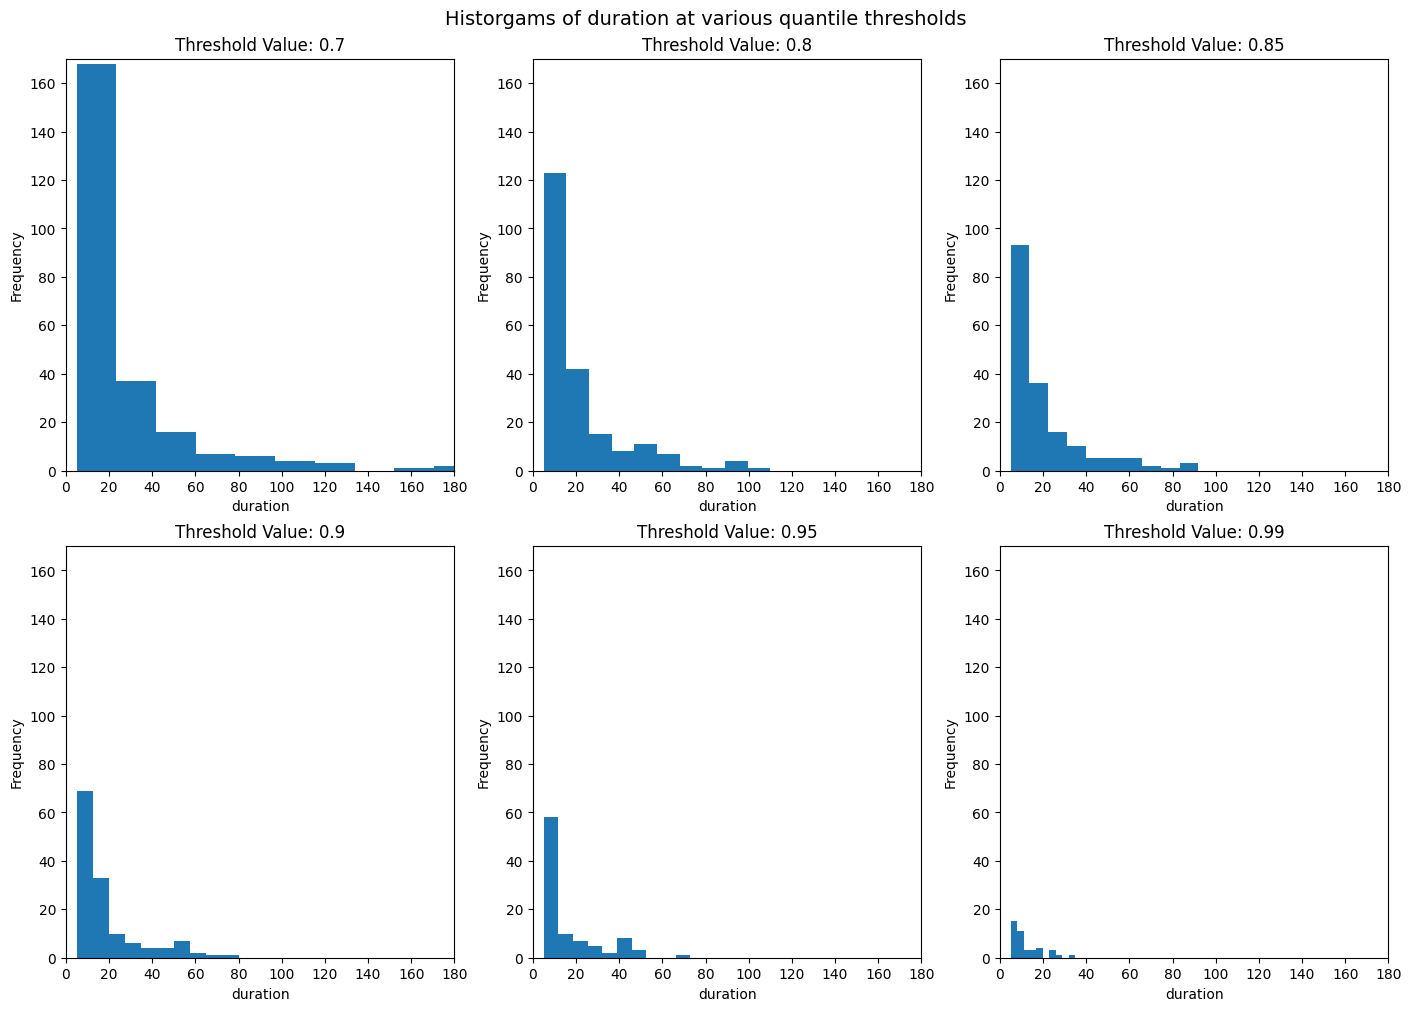

In [268]:
threshold_method = "quantile"
var = "duration"
y_var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,180))
    ax.set_ylim((0,170))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

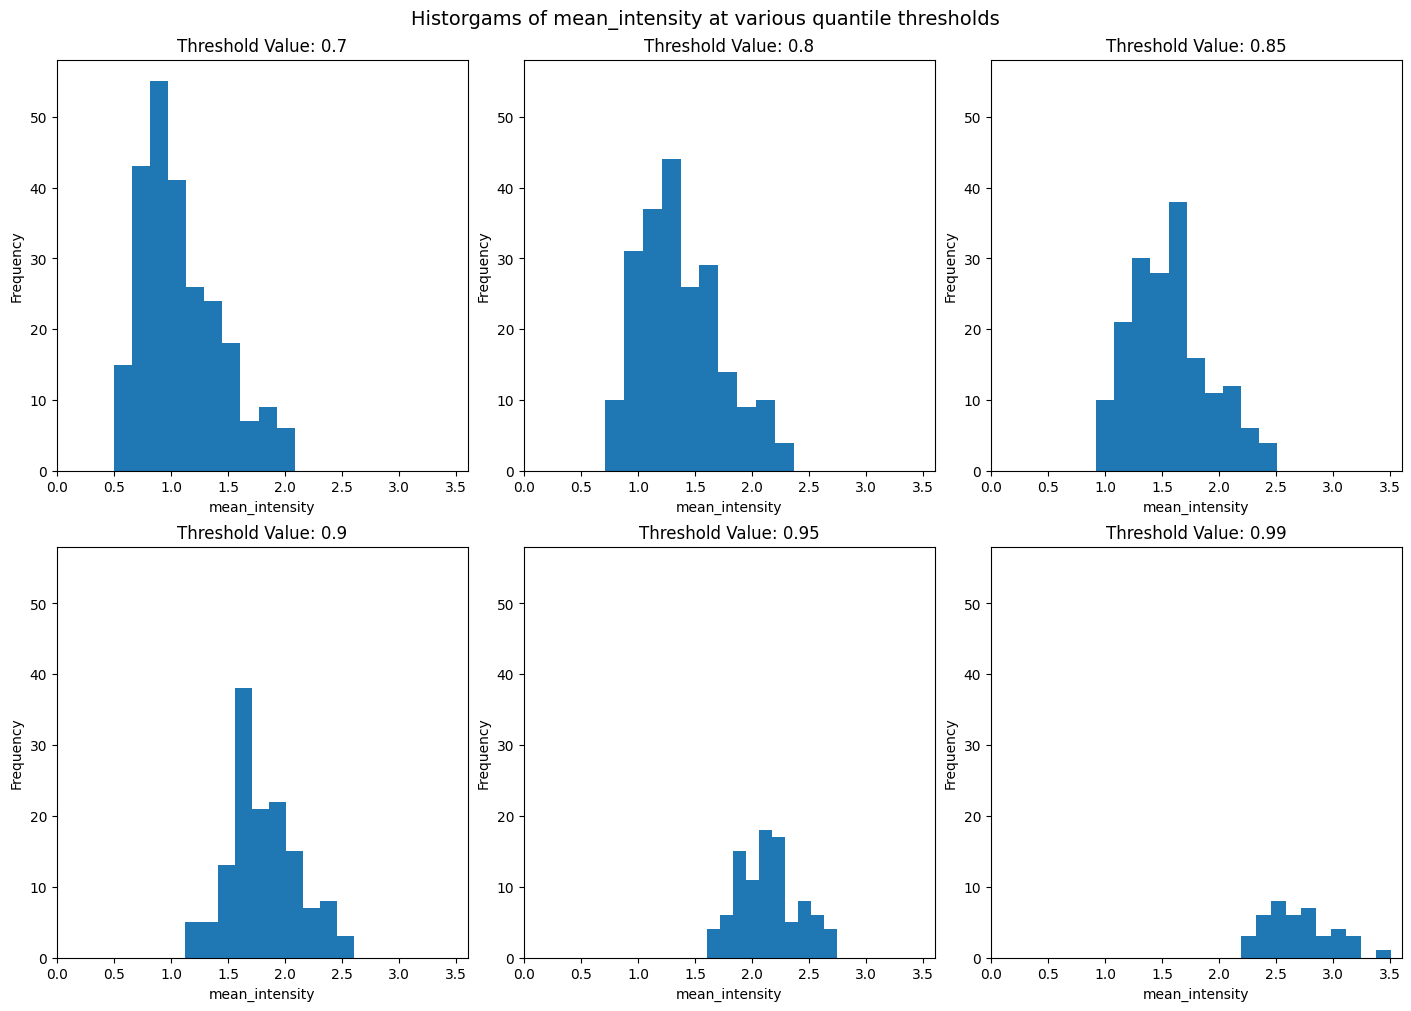

In [264]:
threshold_method = "quantile"
var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,3.6))
    ax.set_ylim((0,58))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

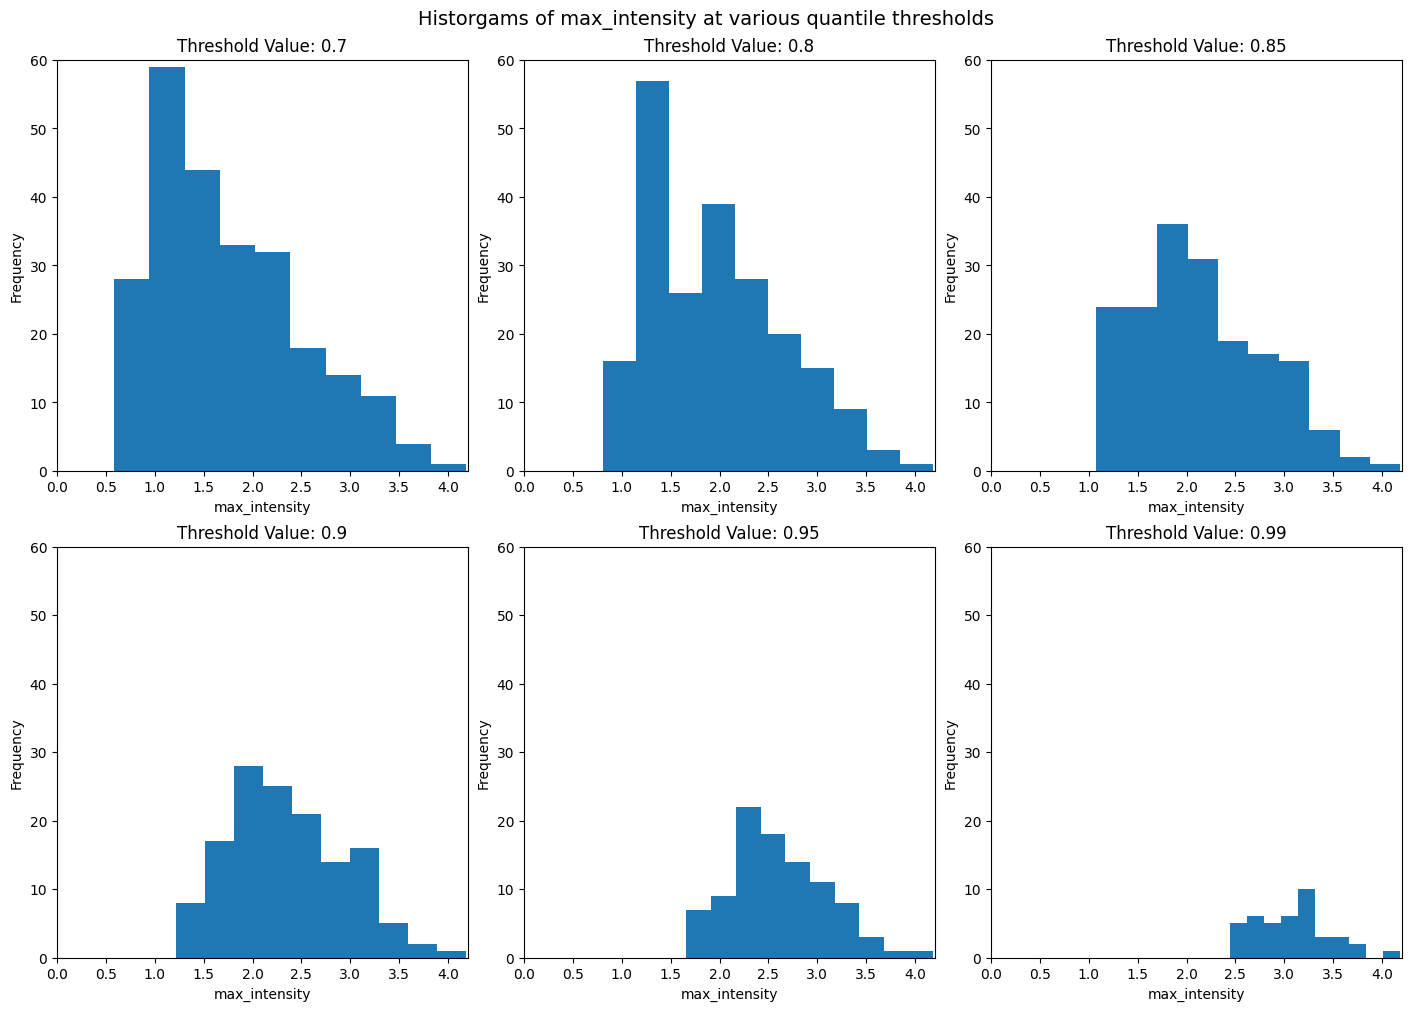

In [ ]:
threshold_method = "quantile"
var = "max_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0, 4.2))
    ax.set_ylim((0, 60))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

### What does this mean? What are the patterns?
- duration has much higher right skewness than mean intensity and max intensity
    - duration skewness remains as threshold is increased
    - max/mean intensity skewness decreases, and distribution becomes more normal, as threshold is increased

## EDA: duration-intensity scatter plots conditional threshold exceedance (for various thresholds) on standardised and non-standardised margins

### Scatter plots at various quantile thresholds

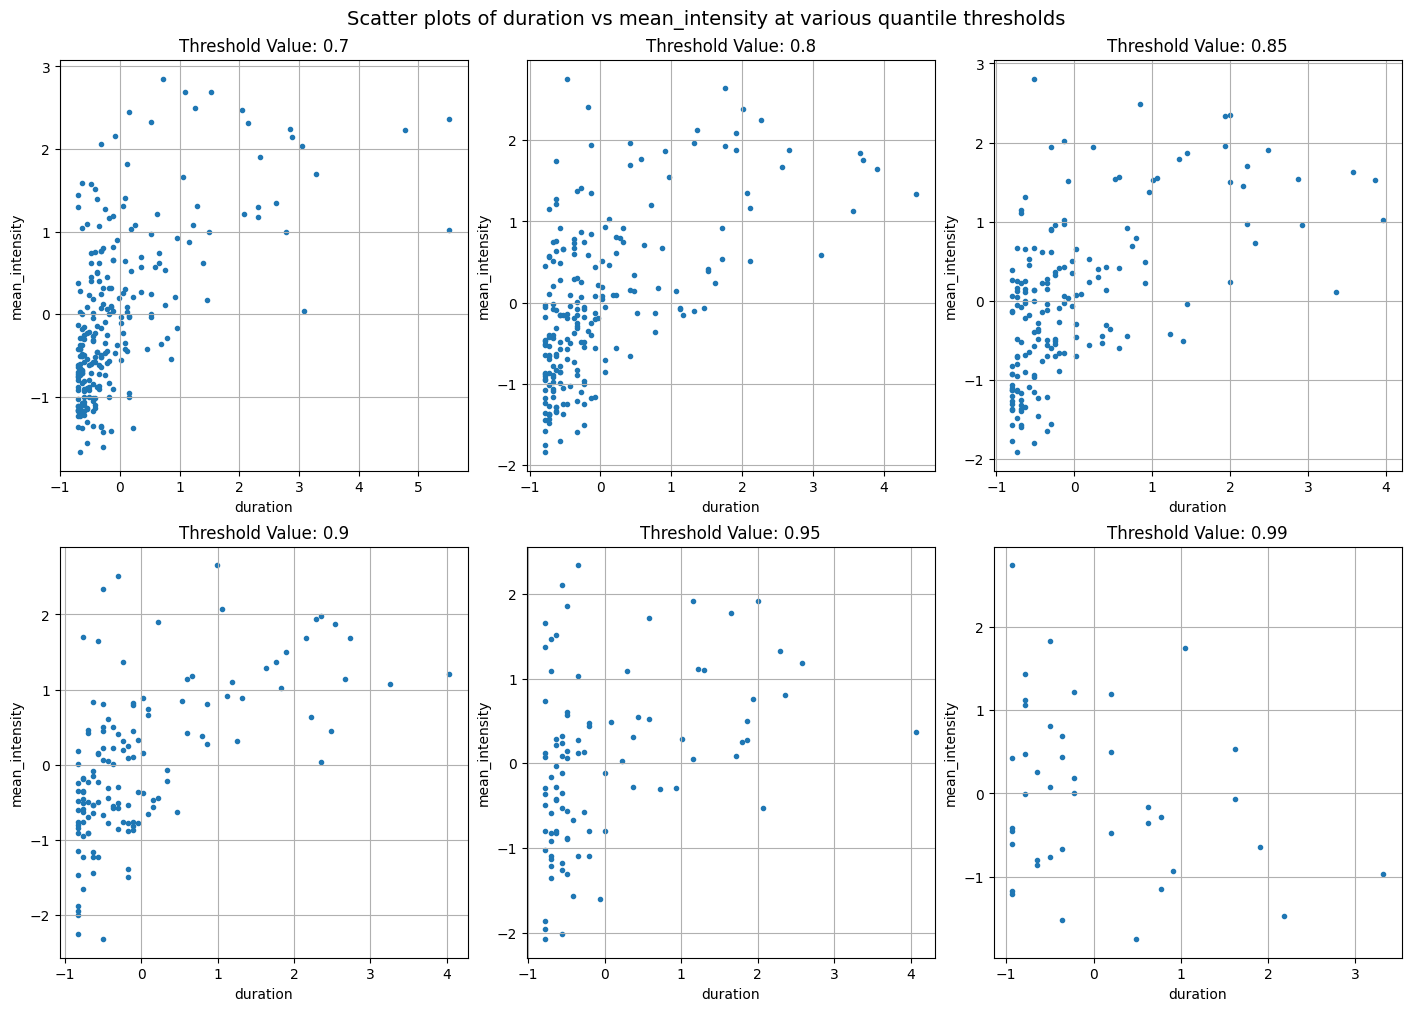

In [269]:
threshold_method = "quantile"
x_var = "duration"
y_var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    df_plot = df.loc[(np.isclose(df["threshold_value"], t_value))]
    if standardise_arrays:
        ax.scatter(standardise(df_plot[x_var]), standardise(df_plot[y_var]), marker='.')
        ax.grid()
    else:
        ax.scatter(df_plot[x_var], df_plot[y_var], marker='.')
    ax.set_xlabel(f"{x_var}")
    ax.set_ylabel(f"{y_var}")
    ax.set_title(f"Threshold Value: {t_value}")
    if not standardise_arrays:
        ax.set_xlim((0,180))
        ax.set_ylim((0,2.6))

fig.suptitle(f"Scatter plots of {x_var} vs {y_var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

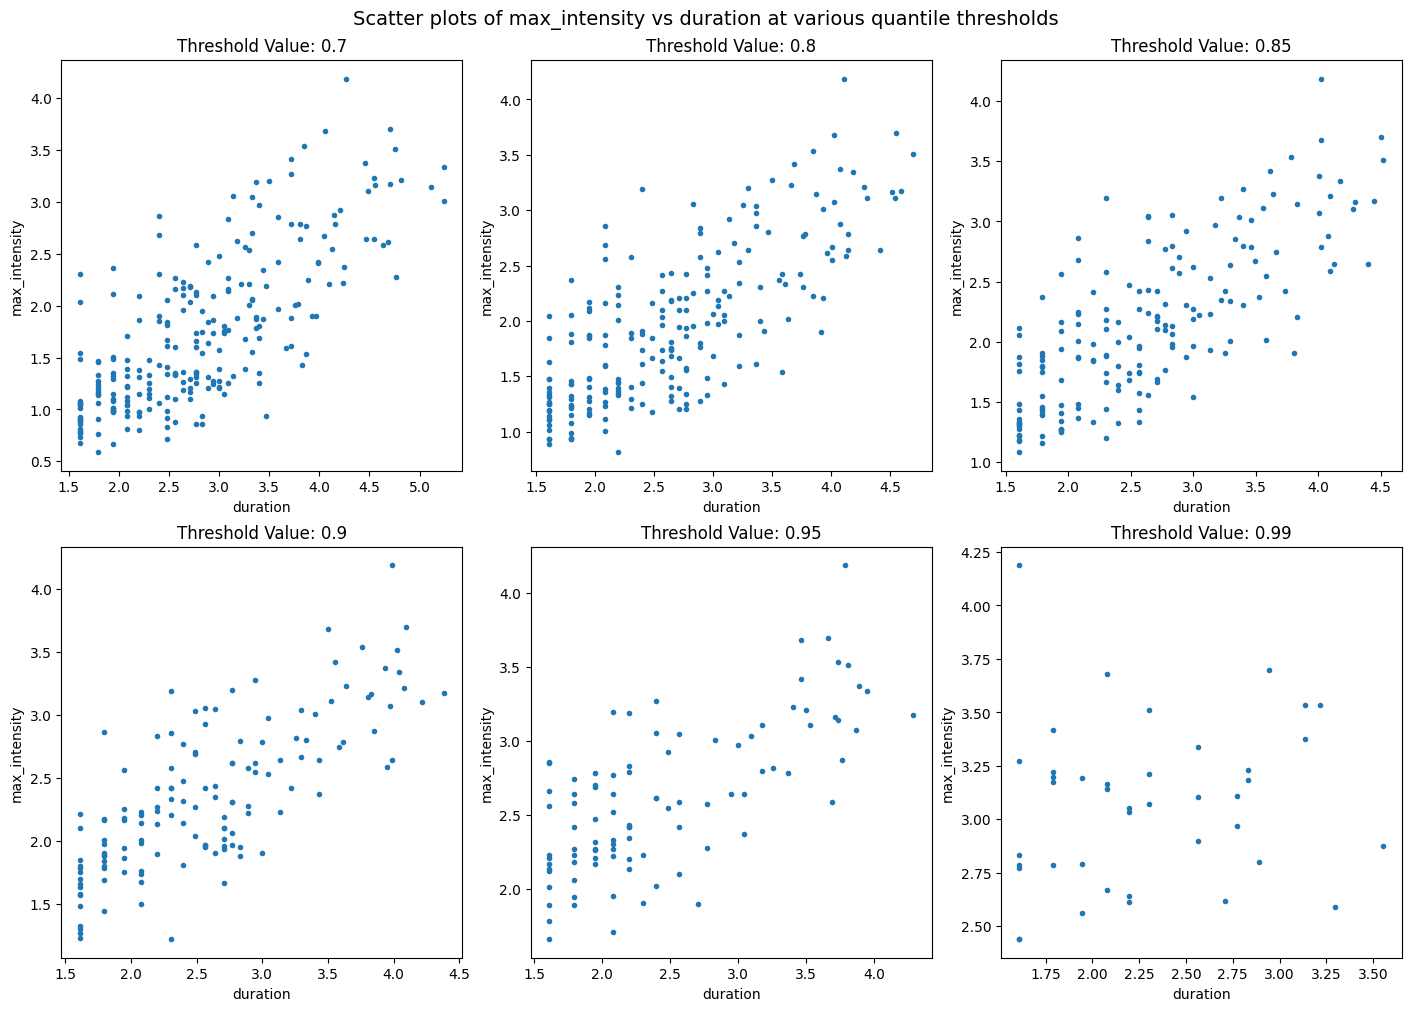

In [ ]:
threshold_method = "quantile"
x_var = "duration"
y_var = "max_intensity"
standardise_arrays = False
log_xvar = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each quantile threshold
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    df_plot = df.loc[(np.isclose(df["threshold_value"], t_value))]
    x_var_arr = df_plot[x_var]
    y_var_arr = df_plot[y_var]

    if log_xvar:
         x_var_arr = np.log(df_plot[x_var])
    if standardise_arrays:
        x_var_arr = standardise(x_var_arr)
        y_var_arr = standardise(y_var_arr)
    # else:
        # ax.set_xlim((0,180))
        # ax.set_ylim((0,4.25))
        
    ax.scatter(x_var_arr, y_var_arr, marker='.')
    ax.set_xlabel(f"{x_var}")
    ax.set_ylabel(f"{y_var}")
    ax.set_title(f"Threshold Value: {t_value}")

fig.suptitle(f"Scatter plots of {y_var} vs {x_var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

### What does this mean? What are the patterns?
- there are more long events with relatively low max intensity than there are long events with relatively high max intensity (relative in terms of standard deviations from their respective means)
- almost logarithmic relationship between max_intensity and duration
    - max_intensity vs log(duration) appears linear

## Plot of Empirical Annual Joint Exceedance Probability and Return Period of MHW Duration and Quantile Threshold

### How these figures were made
1. Set a percentile exeedance threshold
2. From the dataset of MHW events at the surface, select the exceedance events for the threshold over the entire time period 45 years)
3. For each duration $d$ between the minimum and maximum for the observed events, iterate over all years
4. Count the number of years in which there is an event of at least duration $d$
5. Divide the number of years with qualifying events by the total number of years

### What these figures show mathematically

Probability of any year containing an MHW of duration at least $d$ days and with minumim temperature $T_{min}$ surpassing the specified threshold $q$ $$\mathbb{P}(D \ge d, T_{{min}} \geq q)$$

and the associated return period is obtained by inverting the exceedance probability $$T_{d,q} = 1/\mathbb{P}(D \ge d , T_{{min}} \geq q).$$

The annual probability is estimated by $$\hat{\mathbb{P}}(D \ge d, T_{{min}} \geq q) \simeq \frac{\# \text{years with qualifying events}}{\# \text{years}}$$ 

for $d \in \{ 5,6,...,124 \}$ and $q \in \{q_p : p=0.7,0.701,...,0.999\}.$

### What these figure tells us

- Compared to the conditional duration exceedance probability plot above:
    - Lower probability values for joint exceedance events in the lower left quadrant (shorter and less intense events), compared to the conditional duration exceedance probability
    - Similar probability values for extreme events (in both duration and "mininum intensity") probably reflect a lack of event data as opposed to near equality of conditional and joint probabilities

### Analogies in literature

- Figure 11 in "Return period of bivariate distributed extreme hydrological events" (Shiau, 2003)
    - Shows annual joint return period of a flood based on flood volume (mean intensity) and flood peak (max intensity)

![Joint RP of flood volume and peak](./images/jointRP_flood_vol_peak.png)

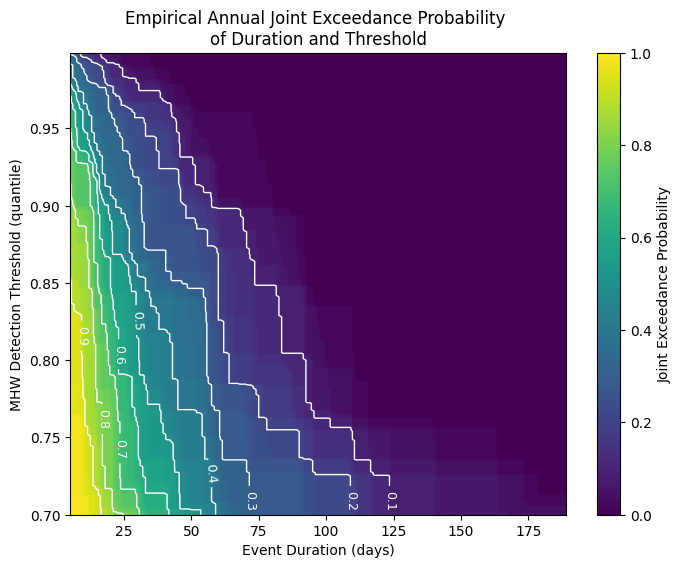

In [159]:
threshold_method = "quantile"
num_years = (daily.time.dt.year[-1] - daily.time.dt.year[0]).item()
df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

# add start date of MHW events
df["year"] = df["start_date"].dt.year
# get list of all percentiles and durations
all_percentiles = np.sort(df["threshold_value"].unique())
dur_min, dur_max = int(df["duration"].min()), int(df["duration"].max())
all_durations = np.arange(dur_min, dur_max + 1)

# Maximum event duration in each year for each exact percentile
annual_max_duration_by_pc = (
    df.groupby(["year", "threshold_value"])["duration"]
    .max()
    .unstack("threshold_value")
    .reindex(columns=all_percentiles)
)

# For each year and percentile p, 
# max duration of any event with percentile >= p using cumulative maximum
annual_max_duration_threshold = (
    annual_max_duration_by_pc
    .reindex(columns=all_percentiles[::-1])
    .cummax(axis=1)
    .reindex(columns=all_percentiles)
)

# Boolean array of duration > d for every year, percentile and duration
# [:, :, None] adds new dimension to array so 
# annual_max_duration_threshold (34, 300) → (34, 300, 1)
# and all_durations (120,) → (1, 1, 120)
# numpy broadcasts dims of size 1 automatically
joint_exceedances = annual_max_duration_threshold.to_numpy()[:, :, None] >= all_durations[None, None, :]

# Annual joint exceedance probability: sum over all years and divide by total # years
# to get array with shape (percentiles, durations)
joint_probability = joint_exceedances.sum(axis=0) / num_years

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(joint_probability, aspect='auto', origin='lower', extent=[dur_min, dur_max, all_percentiles[0],\
    all_percentiles[-1]], cmap='viridis', vmin=0, vmax=1)
contours = ax.contour(all_durations, all_percentiles, joint_probability, 
                        levels=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], colors='white', linewidths=1)
ax.clabel(contours, inline=True, fontsize=9)#, fmt='%.1f')
ax.set_ylabel(f"MHW Detection Threshold ({threshold_method})")
ax.set_xlabel("Event Duration (days)")
ax.set_title("Empirical Annual Joint Exceedance Probability \nof Duration and Threshold")
ax.figure.colorbar(ax.images[0], label=f"Joint Exceedance Probability") #$\hat{{\mathbb{{P}}}}(D \geq d, T_{{min}} \geq q{p})$ ")

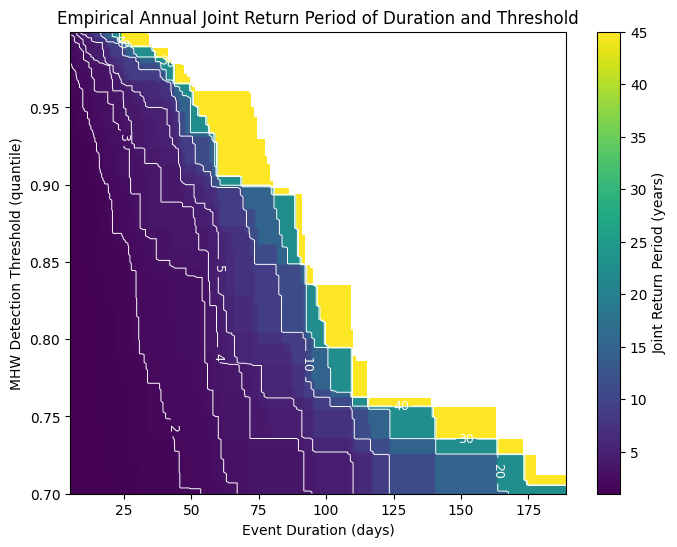

In [161]:
# return period
joint_rp = np.divide(1, joint_probability)
# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(joint_rp, aspect='auto', origin='lower', extent=[dur_min, dur_max, all_percentiles[0],\
    all_percentiles[-1]], cmap='viridis')
contours = ax.contour(all_durations, all_percentiles, joint_rp, levels=[2,3,4,5,10,20,30,40], colors='white', linewidths=0.7)
ax.clabel(contours, inline=True, fontsize=9)#, fmt='%.1f')
ax.set_ylabel(f"MHW Detection Threshold ({threshold_method})")
ax.set_xlabel("Event Duration (days)")
ax.set_title("Empirical Annual Joint Return Period of Duration and Threshold")
ax.figure.colorbar(ax.images[0], label=f"Joint Return Period (years)")